# Modeling

Five model families, each tuned by cross-validation on the training set. The test set is opened once, in the final section.

## 1) Setup

### 1.1) Loading the split and the preprocessors

`02_preprocessing.ipynb` saved the cleaned 80/20 split and the two preprocessor definitions. The definitions are unfitted: each one is refit on the training part of every cross-validation fold, inside the pipeline it belongs to.

In [1]:
import joblib
import numpy as np
import pandas as pd

RANDOM_STATE = 42
PROCESSED_DIR = "../data/processed"
MODELS_DIR = "../models"
REPORTS_DIR = "../reports"

train = joblib.load(f"{PROCESSED_DIR}/train.joblib")
test = joblib.load(f"{PROCESSED_DIR}/test.joblib")

X_train, y_train = train.drop(columns="TARGET"), train["TARGET"]
X_test, y_test = test.drop(columns="TARGET"), test["TARGET"]

preprocessor_linear = joblib.load(f"{MODELS_DIR}/preprocessor_linear.joblib")
preprocessor_tree = joblib.load(f"{MODELS_DIR}/preprocessor_tree.joblib")

for name, X_part, y_part in [("train", X_train, y_train), ("test", X_test, y_test)]:
    print(f"{name:<6}{len(X_part):>8,} rows   {X_part.shape[1]:>3} features   "
          f"default rate {y_part.mean():.4f}")

train  246,003 rows    60 features   default rate 0.0807
test    61,501 rows    60 features   default rate 0.0807


### 1.2) Cross-validation

One `StratifiedKFold` object, reused by every search below, so each family is scored on identical folds and the means are directly comparable. Both metrics are computed per fold; PR-AUC decides which configuration wins.

In [2]:
from sklearn.model_selection import StratifiedKFold

N_SPLITS = 5
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

SCORING = {"ap": "average_precision", "roc": "roc_auc"}
REFIT = "ap"

held_out = len(next(iter(cv.split(X_train, y_train)))[1])
print(f"{N_SPLITS}-fold stratified cross-validation on the training set")
print(f"  fit on   {len(X_train) - held_out:,} rows per fold")
print(f"  score on {held_out:,} rows per fold")
print(f"\nno-skill floors   PR-AUC {y_train.mean():.4f} (the positive rate)   ROC-AUC 0.5000")

5-fold stratified cross-validation on the training set
  fit on   196,802 rows per fold
  score on 49,201 rows per fold

no-skill floors   PR-AUC 0.0807 (the positive rate)   ROC-AUC 0.5000


### 1.3) Pipeline shapes

Three wrappers, one per representation. Each joins a preprocessor to a model in a single estimator, which is what lets the search refit the preprocessor on every fold.

XGBoost and LightGBM read a pandas `category` dtype rather than integer codes, so a cast step sits between the two.

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

SCALE_POS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()


def as_categorical(X):
    """Integer codes -> pandas category dtype. For XGBoost and LightGBM only."""
    X = X.copy()
    for col in X.columns:
        if col.startswith(("categorical__", "ordinal__")):
            X[col] = X[col].astype("int8").astype("category")
    return X


def linear_pipe(model):
    """Logistic Regression: median impute, scale, one-hot."""
    return Pipeline([("prep", preprocessor_linear), ("model", model)])


def tree_pipe(model):
    """Decision Tree, Random Forest: integer codes, NaN kept."""
    return Pipeline([("prep", preprocessor_tree), ("model", model)])


def boost_pipe(model):
    """XGBoost, LightGBM: integer codes recast as pandas category."""
    return Pipeline([
        ("prep", preprocessor_tree),
        ("cast", FunctionTransformer(as_categorical)),
        ("model", model),
    ])


print(f"scale_pos_weight = {SCALE_POS_WEIGHT:.3f}")

scale_pos_weight = 11.387


### 1.4) The search helper

`scoring`, `refit`, `cv` and `return_train_score` are set in one place, so no family is evaluated on different terms from another. `n_iter=None` runs an exhaustive grid, any other value samples that many configurations.

Each call records one row: the winning configuration's cross-validated mean and standard deviation, its training score, and what the search cost.

`save_model` writes the refit winner to `models/` (each saved object is the whole pipeline).

In [4]:
import os
import time
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

results = []


def run_search(name, pipe, space, n_iter=None, n_jobs=8):
    """Tune one family on the training set. n_iter=None -> exhaustive grid."""
    shared = dict(scoring=SCORING, refit=REFIT, cv=cv, return_train_score=True, n_jobs=n_jobs)
    if n_iter is None:
        search = GridSearchCV(pipe, space, **shared)
    else:
        search = RandomizedSearchCV(pipe, space, n_iter=n_iter,
                                    random_state=RANDOM_STATE, **shared)

    start = time.perf_counter()
    search.fit(X_train, y_train)
    wall = time.perf_counter() - start

    cv_res, best = search.cv_results_, search.best_index_
    row = {
        "model": name,
        "cv_ap": cv_res["mean_test_ap"][best],
        "cv_ap_std": cv_res["std_test_ap"][best],
        "cv_roc": cv_res["mean_test_roc"][best],
        "cv_gini": 2 * cv_res["mean_test_roc"][best] - 1,
        "train_ap": cv_res["mean_train_ap"][best],
        "candidates": len(cv_res["params"]),
        "wall_min": wall / 60,
        "best_params": search.best_params_,
    }
    results[:] = [r for r in results if r["model"] != name] + [row] 

    print(f"\n{'='*58}")
    print(f"{name}")
    print(f"{'='*58}")
    print(f"  CV PR-AUC    {row['cv_ap']:.4f} ± {row['cv_ap_std']:.4f}")
    print(f"  CV ROC-AUC   {row['cv_roc']:.4f}")
    print(f"  CV Gini      {row['cv_gini']:.4f}")
    print(f"  train PR-AUC {row['train_ap']:.4f}   gap {row['train_ap'] - row['cv_ap']:+.4f}")
    print(f"  {row['candidates']} candidates x {N_SPLITS} folds in {row['wall_min']:.1f} min")
    for key, value in search.best_params_.items():
        shown = f"{value:g}" if isinstance(value, (float, np.floating)) else value
        print(f"    {key.replace('model__', '')} = {shown}")     
    return search


def save_model(search, filename):
    """Persist the refit winner: a full pipeline, cleaned applicant in, score out."""
    path = f"{MODELS_DIR}/{filename}"
    joblib.dump(search.best_estimator_, path)
    size_kb = os.path.getsize(path) / 1e3
    size, unit = (size_kb / 1e3, "MB") if size_kb >= 1e3 else (size_kb, "KB")
    print(f"saved {path}   {size:.1f} {unit}")

## 2) Models

### 2.1) Logistic Regression

One grid over the strength of the penalty (`C`) and its composition (`l1_ratio`) — 0 is pure L2, 1 is pure L1, 0.5 an even elastic-net mix. The `saga` solver handles all three and is stable for large dataset. `tol=1e-2`, which saga reaches in about 18 iterations.

In [5]:
from sklearn.linear_model import LogisticRegression

logreg_search = run_search(
    "Logistic Regression",
    linear_pipe(LogisticRegression(
        solver="saga",
        max_iter=300,
        tol=1e-2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
    {
        "model__C": [0.01, 0.1, 1.0],
        "model__l1_ratio": [0.0, 0.5, 1.0],
    },
)

save_model(logreg_search, "logreg.joblib")


Logistic Regression
  CV PR-AUC    0.2204 ± 0.0036
  CV ROC-AUC   0.7449
  CV Gini      0.4897
  train PR-AUC 0.2211   gap +0.0008
  9 candidates x 5 folds in 1.8 min
    C = 1
    l1_ratio = 1
saved ../models/logreg.joblib   23.7 KB


#### 2.1.1) Coefficients of the winning configuration

The numeric branch is standardised, so each coefficient is the change in log-odds of default per one standard deviation of that feature, and `exp(coefficient)` is the multiplicative change in the odds.

In [6]:
best_logreg = logreg_search.best_estimator_
feature_names = best_logreg.named_steps["prep"].get_feature_names_out()
coefficients = pd.Series(best_logreg.named_steps["model"].coef_[0], index=feature_names)

print(f"{len(coefficients)} features in   "
      f"{int((coefficients == 0).sum())} zeroed by the penalty\n")

top = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(15)
print(pd.DataFrame({"coefficient": top, "odds_ratio": np.exp(top)}).to_string(
    formatters={"coefficient": "{:+.3f}".format, "odds_ratio": "{:.3f}".format}))

96 features in   0 zeroed by the penalty

                                                 coefficient odds_ratio
numeric__EXT_SOURCE_3                                 -0.489      0.613
numeric__EXT_SOURCE_2                                 -0.392      0.676
categorical__CODE_GENDER_M                            +0.322      1.381
categorical__FLAG_OWN_CAR_Y                           -0.242      0.785
categorical__NAME_CONTRACT_TYPE_Revolving loans       -0.236      0.789
numeric__EXT_SOURCE_1                                 -0.201      0.818
flags__IS_MISSING_AMT_REQ_CREDIT_BUREAU               +0.190      1.209
flags__IS_MISSING_EXT_SOURCE_1                        +0.189      1.208
categorical__NAME_FAMILY_STATUS_Married               -0.174      0.840
numeric__EMPLOYMENT_YEARS                             -0.148      0.863
ordinal__NAME_EDUCATION_TYPE                          -0.146      0.864
flags__FLAG_DOCUMENT_3                                +0.132      1.141
categorical__EMERGENCY

### 2.2) Decision Tree

`min_samples_leaf` is a fraction of the fold, so it rescales with the data; the three values put roughly 16, 79 and 159 defaulters in a leaf, which is the range over which a leaf's default rate goes from noise to a usable estimate. `max_depth` steps 4 to 12 because capacity doubles with every level, with `None` included so the grid can reject a depth cap outright.

In [7]:
from sklearn.tree import DecisionTreeClassifier

TREE_SPACE = {
    "model__max_depth": [4, 6, 8, 12, None],
    "model__min_samples_leaf": [0.001, 0.005, 0.01],
}

tree_search = run_search(
    "Decision Tree",
    tree_pipe(DecisionTreeClassifier(
        class_weight="balanced", 
        random_state=RANDOM_STATE)),
    TREE_SPACE,
)

save_model(tree_search, "tree.joblib")


Decision Tree
  CV PR-AUC    0.1949 ± 0.0016
  CV ROC-AUC   0.7197
  CV Gini      0.4395
  train PR-AUC 0.2073   gap +0.0124
  15 candidates x 5 folds in 2.0 min
    max_depth = None
    min_samples_leaf = 0.005
saved ../models/tree.joblib   39.9 KB


### 2.3) Random Forest

`n_estimators` is fixed at 200 to keep the search cost manageable. `RandomizedSearchCV` samples 10 of the 54 possible combinations across `max_features`, `max_samples`, `max_depth`, and `min_samples_leaf`, balancing computational cost, tree diversity, and model complexity.

In [8]:
from sklearn.ensemble import RandomForestClassifier

RF_SPACE = {
    "model__max_features": ["sqrt", 0.3],
    "model__max_samples": [0.2, 0.3, 0.5],
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [0.0005, 0.001, 0.005],
}

rf_search = run_search(
    "Random Forest",
    tree_pipe(RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced_subsample",
        n_jobs=1,  # run_search already runs one fit per core; nesting the two oversubscribes
        random_state=RANDOM_STATE,
    )),
    RF_SPACE,
    n_iter=10,
)

save_model(rf_search, "random_forest.joblib")


Random Forest
  CV PR-AUC    0.2225 ± 0.0040
  CV ROC-AUC   0.7431
  CV Gini      0.4862
  train PR-AUC 0.2583   gap +0.0358
  10 candidates x 5 folds in 16.5 min
    min_samples_leaf = 0.0005
    max_samples = 0.3
    max_features = 0.3
    max_depth = None
saved ../models/random_forest.joblib   12.3 MB


#### 2.3.1) Feature importance

These scores lean towards continuous and high-cardinality columns, which offer more candidate split points and so win more splits than a binary flag of equal value. They show what the forest used, not what matters — permutation importance answers that, but it needs held-out data, so it waits for the test-set section.

60 features in   3 never chosen for a split   top 10 hold 77.6% of the total


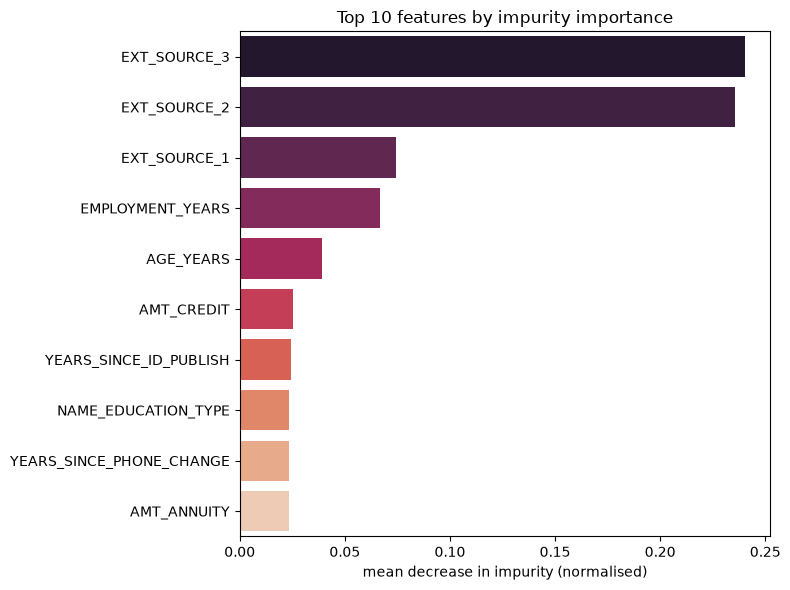

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

best_rf = rf_search.best_estimator_
rf_features = best_rf.named_steps["prep"].get_feature_names_out()
importances = pd.Series(best_rf.named_steps["model"].feature_importances_, index=[n.split("__", 1)[1] for n in rf_features])

print(f"{len(importances)} features in   "
      f"{int((importances == 0).sum())} never chosen for a split   "
      f"top 10 hold {importances.nlargest(10).sum():.1%} of the total")

top = importances.nlargest(10)

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(y=top.index, x=top.values, ax=ax, hue=top.index, palette="rocket")
ax.set_xlabel("mean decrease in impurity (normalised)")
ax.set_ylabel("")
ax.set_title("Top 10 features by impurity importance")
fig.tight_layout()
fig.savefig(f"{REPORTS_DIR}/figures/rf_feature_importance.png", dpi=150)
plt.show()

### 2.4) XGBoost

`scale_pos_weight` accounts for class imbalance. `learning_rate=0.05` and `n_estimators=300` are fixed to limit search cost, focusing the search on tree complexity and sampling. `max_depth` and `min_child_weight` control model complexity, with the latter constraining the Hessian mass required to create a leaf rather than its raw sample count. `subsample` and `colsample_bytree` introduce stochasticity to help reduce overfitting. 

In [10]:
from xgboost import XGBClassifier

XGB_SPACE = {
    "model__max_depth": [3, 5, 7],
    "model__min_child_weight": [1, 10, 50],
    "model__subsample": [0.5, 0.7],
    "model__colsample_bytree": [0.3, 0.5],
}

xgb_search = run_search(
    "XGBoost",
    boost_pipe(XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        scale_pos_weight=SCALE_POS_WEIGHT,
        enable_categorical=True,
        tree_method="hist",
        n_jobs=1,  # run_search already runs one fit per core; nesting the two oversubscribes
        random_state=RANDOM_STATE,
    )),
    XGB_SPACE,
    n_iter=10
)

save_model(xgb_search, "xgboost.joblib")


XGBoost
  CV PR-AUC    0.2397 ± 0.0048
  CV ROC-AUC   0.7548
  CV Gini      0.5096
  train PR-AUC 0.3640   gap +0.1243
  10 candidates x 5 folds in 7.7 min
    subsample = 0.7
    min_child_weight = 50
    max_depth = 7
    colsample_bytree = 0.5
saved ../models/xgboost.joblib   1.9 MB


### 2.5) LightGBM

`num_leaves` controls tree complexity under LightGBM's leaf-wise growth. `min_child_samples` regularizes leaf size in terms of rows, unlike XGBoost's Hessian-based `min_child_weight`. `subsample_freq=1` activates row sampling; the search tests sampling rates up to 1.0 and feature fractions from 0.3 to 0.8, balancing tree diversity against the information available per tree.

In [11]:
from lightgbm import LGBMClassifier

LGBM_SPACE = {
    "model__num_leaves": [15, 31, 63],
    "model__min_child_samples": [50, 200, 800],
    "model__colsample_bytree": [0.3, 0.5, 0.8],
    "model__subsample": [0.7, 0.85, 1.0],
}

lgbm_search = run_search(
    "LightGBM",
    boost_pipe(LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        scale_pos_weight=SCALE_POS_WEIGHT,
        subsample_freq=1,  # without this, subsample is silently ignored
        n_jobs=1,  # run_search already runs one fit per core; nesting the two oversubscribes
        random_state=RANDOM_STATE,
        verbose=-1,
    )),
    LGBM_SPACE,
    n_iter=10,
)

save_model(lgbm_search, "lightgbm.joblib")


LightGBM
  CV PR-AUC    0.2412 ± 0.0050
  CV ROC-AUC   0.7568
  CV Gini      0.5137
  train PR-AUC 0.2867   gap +0.0455
  10 candidates x 5 folds in 4.8 min
    subsample = 0.85
    num_leaves = 31
    min_child_samples = 800
    colsample_bytree = 0.3
saved ../models/lightgbm.joblib   1.1 MB


### 2.6) Comparison table

In [35]:
MODELS = {
    "Logistic Regression": logreg_search,
    "Decision Tree": tree_search,
    "Random Forest": rf_search,
    "XGBoost": xgb_search,
    "LightGBM": lgbm_search,
}

comparison = pd.DataFrame([
    {
        "Model": name,
        "PR-AUC": s.cv_results_["mean_test_ap"][s.best_index_],
        "PR-AUC std": s.cv_results_["std_test_ap"][s.best_index_],
        "ROC-AUC": s.cv_results_["mean_test_roc"][s.best_index_],
        "Gini": 2 * s.cv_results_["mean_test_roc"][s.best_index_] - 1
    }
    for name, s in MODELS.items()
])

(comparison.style
    .format({c: "{:.4f}" for c in comparison.columns if c != "Model"})
    .highlight_max(subset=["PR-AUC", "ROC-AUC", "Gini"], color="#359d4a")
    .highlight_min(subset=["PR-AUC std"], color="#359d4a"))

,Model,PR-AUC,PR-AUC std,ROC-AUC,Gini
0,Logistic Regression,0.2204,0.0036,0.7449,0.4897
1,Decision Tree,0.1949,0.0016,0.7197,0.4395
2,Random Forest,0.2225,0.0040,0.7431,0.4862
3,XGBoost,0.2397,0.0048,0.7548,0.5096
4,LightGBM,0.2412,0.0050,0.7568,0.5137


## 3) Final evaluation

### 3.1) Out-of-fold predictions

In [36]:
from sklearn.model_selection import cross_val_predict

WINNER = comparison.loc[comparison["PR-AUC"].idxmax(), "Model"]
print("winner on CV PR-AUC:", WINNER)
print()

oof = {}
for name in [WINNER] + [m for m in MODELS if m != WINNER]:
    start = time.perf_counter()
    oof[name] = cross_val_predict(MODELS[name].best_estimator_, X_train, y_train,
                                  cv=cv, method="predict_proba", n_jobs=5)[:, 1]
    print(f"  {name:<20}{(time.perf_counter() - start) / 60:5.1f} min")

winner on CV PR-AUC: LightGBM

  LightGBM              0.5 min
  Logistic Regression   0.3 min
  Decision Tree         0.4 min
  Random Forest         2.9 min
  XGBoost               1.1 min


In [39]:
from sklearn.metrics import average_precision_score

fold_means = [oof[WINNER][test_idx].mean() for _, test_idx in cv.split(X_train, y_train)]
print("mean OOF score by fold   " + "  ".join(f"{m:.4f}" for m in fold_means))
print(f"spread, max - min        {max(fold_means) - min(fold_means):.4f}")
print()

check = comparison[["Model", "PR-AUC"]].copy()
check["OOF PR-AUC"] = [average_precision_score(y_train, oof[m]) for m in check["Model"]]
check["difference"] = check["OOF PR-AUC"] - check["PR-AUC"]
print(check.to_string(index=False, float_format="{:.4f}".format))

mean OOF score by fold   0.4003  0.3997  0.4016  0.4017  0.4000
spread, max - min        0.0020

              Model  PR-AUC  OOF PR-AUC  difference
Logistic Regression  0.2204      0.2200     -0.0004
      Decision Tree  0.1949      0.1958      0.0009
      Random Forest  0.2225      0.2220     -0.0005
            XGBoost  0.2397      0.2393     -0.0004
           LightGBM  0.2412      0.2408     -0.0004


### 3.2) Comparison curves

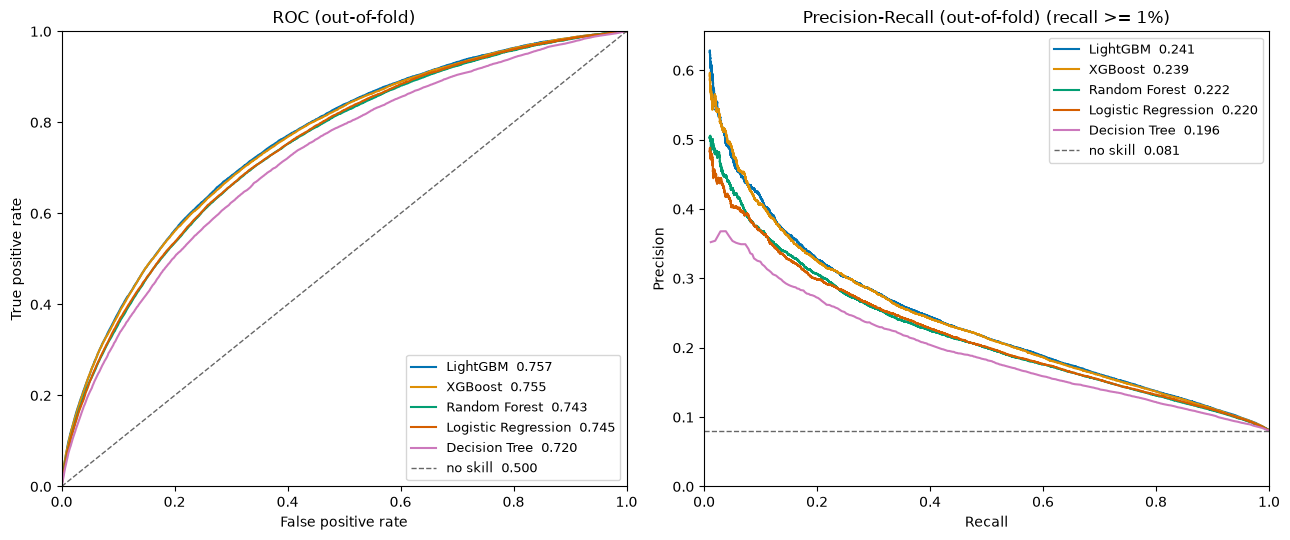

In [49]:
from sklearn.metrics import precision_recall_curve, roc_auc_score, roc_curve

RECALL_FLOOR = 0.01

ORDER = comparison.sort_values("PR-AUC", ascending=False)["Model"].tolist()
BASE_RATE = y_train.mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for color, name in zip(sns.color_palette("colorblind", len(ORDER)), ORDER):
    scores = oof[name]

    fpr, tpr, _ = roc_curve(y_train, scores)
    axes[0].plot(fpr, tpr, color=color, lw=1.5,
                 label=f"{name}  {roc_auc_score(y_train, scores):.3f}")

    precision, recall, _ = precision_recall_curve(y_train, scores, drop_intermediate=True)
    shown = recall >= RECALL_FLOOR
    axes[1].plot(recall[shown], precision[shown], color=color, lw=1.5,
                 label=f"{name}  {average_precision_score(y_train, scores):.3f}")

axes[0].plot([0, 1], [0, 1], color="0.4", ls="--", lw=1, label="no skill  0.500")
axes[0].set_title("ROC (out-of-fold)")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].legend(loc="lower right", fontsize=9)

axes[1].axhline(BASE_RATE, color="0.4", ls="--", lw=1, label=f"no skill  {BASE_RATE:.3f}")
axes[1].set_title(f"Precision-Recall (out-of-fold) (recall >= {RECALL_FLOOR:.0%})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, None)
axes[1].legend(loc="upper right", fontsize=9)

fig.tight_layout()
fig.savefig(f"{REPORTS_DIR}/figures/model_comparison_curves.png", dpi=150)
plt.show()